# Who depends on buses?

Which Londoners live away from TfL rail, so that the bus is their main public transport, and who are
they? This notebook joins 2021 small-area data to the bus and rail networks.

**Unit:** the 2021 Lower Layer Super Output Area (LSOA), a small area of typically 1,500-2,000 residents (interquartile range).
London has 4,994. Each LSOA is placed at its **population weighted centroid** (ONS), the point that
best represents where its residents live.

**Data** (downloaded by `data-prep/download_tfl_bus.py demographics`, sources in `data/bus/manifest.csv`):

* Census 2021: usual residents (TS001), car or van availability (TS045), age (TS007a),
  disability under the Equality Act (TS038);
* English Indices of Deprivation 2025 (IMD; deciles are national, 1 = most deprived 10% in England);
* ONS 2021 LSOA population weighted centroids;
* BUSTO 2023-24 and 2025-26 (weekday boardings by stop and route), the TfL bus-stops feed and the
  TfL rail stations of the rail analysis.

**Definitions** (straight-line distances from the centroid):

* **TfL rail nearby:** an Underground, Overground, DLR or Elizabeth line station within **800 m**
  (about a 10-minute walk). National Rail-only stations are **not** counted, as in the rest of the
  analysis, so "no TfL rail nearby" does not mean "no rail": parts of south and outer London are
  served by National Rail. 500 m and 1,200 m are tested in section 5.
* **Bus nearby:** at least one bus stop served by a BUSTO route on weekdays in 2025-26 within **400 m**
  (about a 5-minute walk).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tfl_bus as B

B.RESULTS.mkdir(parents=True, exist_ok=True)
L = B.load_lsoa_london().join(B.lsoa_access(B.load_lsoa_london()))
L['access'] = np.select([L.rail_m <= B.RAIL_WALK_M, L.routes_near > 0],
                        ['TfL rail within 800 m', 'bus only'], 'neither within reach')
GROUPS = ['TfL rail within 800 m', 'bus only', 'neither within reach']

def profile(d):
    """Population-weighted profile of a group of LSOAs (sums of counts, not means of rates)."""
    return pd.Series({
        'LSOAs': len(d),
        'residents': d.residents.sum(),
        'share of London residents (%)': 100 * d.residents.sum() / L.residents.sum(),
        'households with no car or van': d.households_no_car.sum(),
        'households with no car or van (%)': 100 * d.households_no_car.sum() / d.households.sum(),
        'aged 5-19 (%)': 100 * d.aged_5_19.sum() / d.age_total.sum(),
        'aged 65+ (%)': 100 * d.aged_65_plus.sum() / d.age_total.sum(),
        'disabled (%)': 100 * d.disabled.sum() / d.disability_total.sum(),
        'residents in most deprived 20% of England (%)': 100 * d.residents[d.imd_decile <= 2].sum() / d.residents.sum(),
        'median bus routes within 400 m': d.routes_near.median(),
    })

print(f"{len(L):,} LSOAs in {L.borough.nunique()} boroughs, {L.residents.sum():,} residents (Census 2021)")

4,994 LSOAs in 33 boroughs, 8,799,776 residents (Census 2021)


## 1. Who lives away from TfL rail?

In [2]:
groups = L.groupby('access').apply(profile, include_groups=False).reindex(GROUPS)
groups.loc['London'] = profile(L)
groups.T.round(1).to_csv(B.RESULTS / 'who_depends_access_groups.csv')
groups.T.round(1)

access,TfL rail within 800 m,bus only,neither within reach,London
LSOAs,2434.0,2461.0,99.0,4994.0
residents,4301303.0,4334030.0,164443.0,8799776.0
share of London residents (%),48.9,49.3,1.9,100.0
households with no car or van,898631.0,529844.0,11779.0,1440254.0
households with no car or van (%),52.2,32.2,19.8,42.1
aged 5-19 (%),16.5,18.8,19.3,17.7
aged 65+ (%),10.2,13.3,16.6,11.9
disabled (%),13.0,13.5,12.9,13.2
residents in most deprived 20% of England (%),22.1,15.2,8.5,18.5
median bus routes within 400 m,6.0,4.0,0.0,5.0


Half of Londoners (49%) live more than 800 m from a TfL rail station but within 400 m of a bus
route. Almost everyone else has TfL rail nearby; only about 2% have neither (mostly on the edge of
London). The bus-only half is **older, with more children and teenagers, and with more cars** than
the half near rail: rail runs through the dense, inner areas where car-free living is easiest.

By deprivation decile (national IMD 2025 deciles; 1 = most deprived):

In [3]:
def by_group(d):
    return pd.Series({
        'residents': d.residents.sum(),
        'no TfL rail within 800 m (%)': 100 * d.residents[d.rail_m > B.RAIL_WALK_M].sum() / d.residents.sum(),
        'households with no car or van (%)': 100 * d.households_no_car.sum() / d.households.sum(),
        'car-free households with no TfL rail within 800 m': d.households_no_car[d.rail_m > B.RAIL_WALK_M].sum(),
    })

imd = L.groupby('imd_decile').apply(by_group, include_groups=False)
imd.round(1).to_csv(B.RESULTS / 'who_depends_by_imd_decile.csv')
imd.round(1)

,residents,no TfL rail within 800 m (%),households with no car or van (%),car-free households with no TfL rail within 800 m
imd_decile,,,,
1,363073.0,36.1,55.9,22427.0
2,1260597.0,43.1,51.9,82847.0
3,1583141.0,46.0,48.7,105641.0
4,1308587.0,47.1,46.8,83775.0
5,1038000.0,50.4,42.2,66556.0
6,807104.0,52.2,39.9,49774.0
7,725417.0,54.5,36.1,43555.0
8,636143.0,56.4,34.2,34972.0
9,576971.0,66.6,27.7,31895.0


More deprived areas are **more often** near TfL rail (64% of residents in the most deprived decile,
against 21% in the least deprived) and much more often car-free. Deprivation and distance from rail
pull in opposite directions, which is why the bus-only group as a whole is not more deprived.

## 2. Households with no car and no TfL rail nearby

The households that depend on buses most are those with no car or van **and** no TfL rail station
within reach.

In [4]:
nocar = L.households_no_car
far = L.rail_m > B.RAIL_WALK_M
headline = pd.Series({
    'households with no car or van (London)': nocar.sum(),
    '... of which no TfL rail within 800 m': nocar[far].sum(),
    '... share (%)': round(100 * nocar[far].sum() / nocar.sum(), 1),
    '... of which also no bus route within 400 m': nocar[far & (L.routes_near == 0)].sum(),
    '... of those with no TfL rail, in most deprived 20% of England (%)':
        round(100 * nocar[far & (L.imd_decile <= 2)].sum() / nocar[far].sum(), 1),
})
headline.to_csv(B.RESULTS / 'who_depends_headline.csv', header=['value'])
headline

households with no car or van (London)                                1440254.0
... of which no TfL rail within 800 m                                  541623.0
... share (%)                                                              37.6
... of which also no bus route within 400 m                             11779.0
... of those with no TfL rail, in most deprived 20% of England (%)         19.4
dtype: float64

In [5]:
boro = L.groupby('borough').apply(lambda d: pd.Series({
    'residents': d.residents.sum(),
    'no TfL rail within 800 m (%)': 100 * d.residents[d.rail_m > B.RAIL_WALK_M].sum() / d.residents.sum(),
    'households with no car or van (%)': 100 * d.households_no_car.sum() / d.households.sum(),
    'car-free households with no TfL rail within 800 m': d.households_no_car[d.rail_m > B.RAIL_WALK_M].sum(),
}), include_groups=False).sort_values('car-free households with no TfL rail within 800 m', ascending=False)
boro.round(1).to_csv(B.RESULTS / 'who_depends_by_borough.csv')
boro.round(1).head(10)

,residents,no TfL rail within 800 m (%),households with no car or van (%),car-free households with no TfL rail within 800 m
borough,,,,
Croydon,390708.0,90.1,33.6,42508.0
Greenwich,289052.0,77.7,43.1,33845.0
Lambeth,317669.0,50.0,58.0,33686.0
Southwark,307631.0,48.0,60.3,33585.0
Wandsworth,327512.0,51.0,47.9,30652.0
Lewisham,300548.0,57.2,47.7,29565.0
Bromley,329991.0,92.3,22.9,25602.0
Barnet,389348.0,57.9,29.9,23428.0
Hounslow,288175.0,71.0,32.8,21250.0


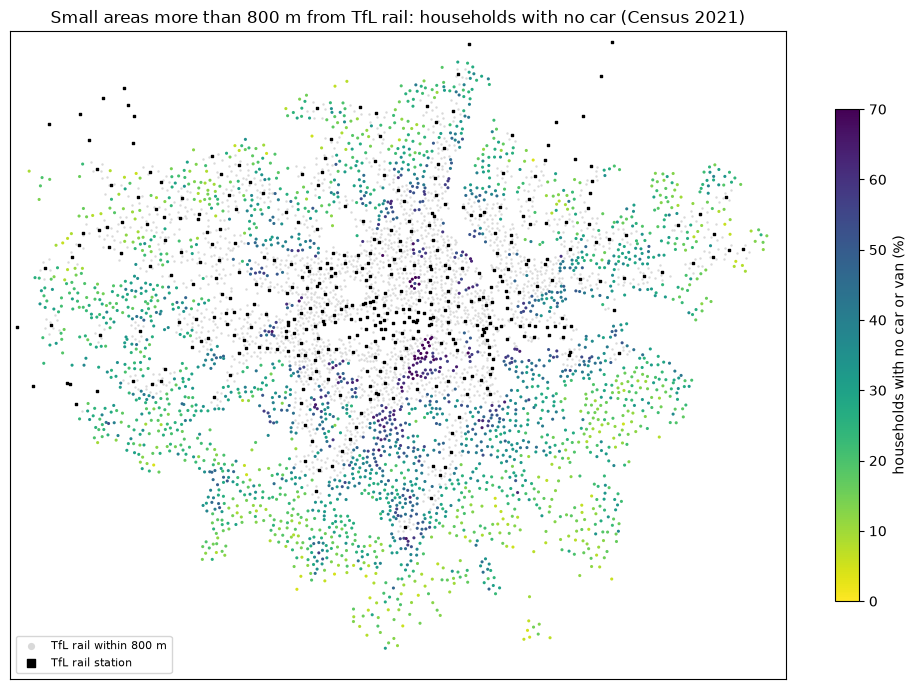

In [6]:
fig, ax = plt.subplots(figsize=(10, 8.5))
dens = L.households_no_car / L.households * 100
ax.scatter(L.lon[~far], L.lat[~far], s=3, color='#d9d9d9', lw=0, label='TfL rail within 800 m')
sc = ax.scatter(L.lon[far], L.lat[far], c=dens[far], cmap='viridis_r', vmin=0, vmax=70, s=5, lw=0)
rail = B.rail_stations()
ax.scatter(rail.lon, rail.lat, s=4, color='black', marker='s', label='TfL rail station')
ax.set_aspect(1 / np.cos(np.radians(51.5))); ax.set_xticks([]); ax.set_yticks([])
ax.set_xlim(L.lon.min() - .02, L.lon.max() + .02); ax.set_ylim(L.lat.min() - .02, L.lat.max() + .02)
plt.colorbar(sc, ax=ax, shrink=.6, label='households with no car or van (%)')
ax.legend(loc='lower left', fontsize=8, markerscale=3)
ax.set_title('Small areas more than 800 m from TfL rail: households with no car (Census 2021)')
plt.tight_layout(); plt.show()

## 3. Bus use near home

BUSTO gives boardings by stop, not by where passengers live. As an approximation, each bus stop is
assigned to the LSOA whose population weighted centroid is nearest, and weekday boardings are
divided by that LSOA's residents. Boardings at stops within 400 m of a TfL rail station are left
out, because those are largely interchange trips by people from elsewhere. This is a measure of
**bus use starting near home**, and it is still noisy: town-centre stops attract people from other
areas.

In [7]:
con = B.busto_con()
sb = con.execute('''SELECT year, stopcode, sum(boardings) AS b FROM qhr
                    WHERE day_type = 'Weekday' AND year IN (2023, 2025) GROUP BY ALL''').df()
sb = sb.pivot(index='stopcode', columns='year', values='b')
cat = B.stops_to_lsoa(L, sb.index)
sb = sb.join(cat, how='inner')
total25 = con.execute("SELECT sum(boardings) FROM qhr WHERE day_type = 'Weekday' AND year = 2025").fetchone()[0]
print(f"{len(sb):,} stops assigned; median distance to the assigned centroid {sb.dist_m.median():.0f} m; "
      f"{100 * sb[2025].sum() / total25:.1f}% of 2025-26 weekday boardings kept")
local = sb[sb.rail_m > B.WALK_M]
L['local_boardings'] = local.groupby('lsoa')[2025].sum().reindex(L.index).fillna(0)

def use(d):
    return pd.Series({'residents': d.residents.sum(),
                      'households with no car or van (%)': 100 * d.households_no_car.sum() / d.households.sum(),
                      'weekday boardings near home per resident': d.local_boardings.sum() / d.residents.sum()})

L['no_car_quintile'] = pd.qcut(L.pct_no_car, 5, labels=['1 (fewest)', '2', '3', '4', '5 (most)'])
use_tab = pd.concat({
    'IMD decile': L.groupby('imd_decile').apply(use, include_groups=False),
    'car-free quintile': L.groupby('no_car_quintile', observed=True).apply(use, include_groups=False),
    'access': L.groupby('access').apply(use, include_groups=False).reindex(GROUPS),
})
use_tab.round(3).to_csv(B.RESULTS / 'who_depends_bus_use.csv')
use_tab.round(3)

18,717 stops assigned; median distance to the assigned centroid 208 m; 99.2% of 2025-26 weekday boardings kept


residents  \
IMD decile        1                       363073.0   
                  2                      1260597.0   
                  3                      1583141.0   
                  4                      1308587.0   
                  5                      1038000.0   
                  6                       807104.0   
                  7                       725417.0   
                  8                       636143.0   
                  9                       576971.0   
                  10                      500743.0   
car-free quintile 1 (fewest)             1655847.0   
                  2                      1805628.0   
                  3                      1795840.0   
                  4                      1804804.0   
                  5 (most)               1737657.0   
access            TfL rail within 800 m  4301303.0   
                  bus only               4334030.0   
                  neither within reach    164443.0   

                                         households with no car or van (%)  \
IMD decile        1                                                 55.896   
                  2                                                 51.902   
                  3                                                 48.658   
                  4                                                 46.761   
                  5                                                 42.238   
                  6                                                 39.879   
                  7                                                 36.066   
                  8                                                 34.229   
                  9                                                 27.668   
                  10                                                16.361   
car-free quintile 1 (fewest)                                        15.290   
                  2                                                 27.562   
                  3                                                 39.102   
                  4                                                 52.777   
                  5 (most)                                          68.359   
access            TfL rail within 800 m                             52.244   
                  bus only                                          32.225   
                  neither within reach                              19.778   

                                         weekday boardings near home per resident  
IMD decile        1                                                         0.468  
                  2                                                         0.422  
                  3                                                         0.398  
                  4                                                         0.343  
                  5                                                         0.318  
                  6                                                         0.345  
                  7                                                         0.320  
                  8                                                         0.268  
                  9                                                         0.221  
                  10                                                        0.160  
car-free quintile 1 (fewest)                                                0.212  
                  2                                                         0.331  
                  3                                                         0.381  
                  4                                                         0.444  
                  5 (most)                                                  0.326  
access            TfL rail within 800 m                                     0.237  
                  bus only                                                  0.456  
                  n

Bus use near home rises steadily with deprivation: residents of the most deprived decile board
about three times as often near home as those in the least deprived. It rises with the share of
car-free households up to the fourth quintile; the most car-free fifth of areas is mostly in inner
London, where TfL rail and walking take a larger share. Bus-only areas have about twice the bus use
near home of areas near TfL rail (0.46 against 0.24 boardings per resident), but part of that gap is
built in: stops near rail stations, which are mostly in the areas near rail, are excluded.

## 4. Has bus demand changed differently by deprivation?

Weekday boardings 2023-24 to 2025-26 at stops served in both years (all stops, including those near
rail). The EDA found an overall fall of about 7%.

In [8]:
both = sb[(sb[2023] > 0) & (sb[2025] > 0)].join(L[['imd_decile', 'centre_km']], on='lsoa')
both['ring'] = np.where(both.centre_km < 10, 'within 10 km of centre', 'beyond 10 km')
chg = lambda d: pd.Series({'stops': len(d), 'boardings 2023-24 (000s)': d[2023].sum() / 1000,
                           'change (%)': 100 * (d[2025].sum() / d[2023].sum() - 1)})
change = pd.concat({'all': both.groupby('imd_decile').apply(chg, include_groups=False)}
                   | {r: both[both.ring == r].groupby('imd_decile').apply(chg, include_groups=False)
                      for r in ['within 10 km of centre', 'beyond 10 km']})
change.round(1).to_csv(B.RESULTS / 'who_depends_change_by_imd.csv')
change['change (%)'].unstack(0).round(1)

,all,within 10 km of centre,beyond 10 km
imd_decile,,,
1,-9.4,-10.2,-8.9
2,-8.7,-11.0,-6.7
3,-7.6,-10.2,-5.4
4,-6.1,-8.2,-4.0
5,-7.8,-10.8,-5.5
6,-4.4,-5.6,-3.0
7,-6.4,-9.1,-3.7
8,-6.4,-9.2,-3.2
9,-2.3,-6.1,-0.4


Bus boardings fell more around the most deprived areas. Part of this is geography (deprived areas
are more central, where demand fell more), so the table splits stops within and beyond 10 km of
Charing Cross; the gradient holds in both. It should be read as descriptive: it mixes changes in
demand with changes in service, and the demand-change notebook found that cuts in capacity explain
part of the overall fall (capacity on continuing route-stops fell 3.3% on weekdays).

## 5. Sensitivity: what counts as "near" TfL rail

In [9]:
sens = pd.DataFrame({r: {
    'residents with no TfL rail within radius (%)': 100 * L.residents[L.rail_m > r].sum() / L.residents.sum(),
    'car-free households with no TfL rail within radius': L.households_no_car[L.rail_m > r].sum(),
    '... share of all car-free households (%)': 100 * L.households_no_car[L.rail_m > r].sum() / L.households_no_car.sum(),
    'most deprived decile: no TfL rail within radius (%)':
        100 * L.residents[(L.rail_m > r) & (L.imd_decile == 1)].sum() / L.residents[L.imd_decile == 1].sum(),
    'least deprived decile: no TfL rail within radius (%)':
        100 * L.residents[(L.rail_m > r) & (L.imd_decile == 10)].sum() / L.residents[L.imd_decile == 10].sum(),
} for r in B.RAIL_WALK_RADII_M})
sens.columns = [f'{r} m' for r in sens.columns]
sens.round(1).to_csv(B.RESULTS / 'who_depends_sensitivity.csv')
sens.round(1)

,500 m,800 m,1200 m
residents with no TfL rail within radius (%),71.7,51.1,34.7
car-free households with no TfL rail within radius,868129.0,541623.0,328828.0
... share of all car-free households (%),60.3,37.6,22.8
most deprived decile: no TfL rail within radius (%),60.1,36.1,15.0
least deprived decile: no TfL rail within radius (%),93.1,79.3,68.3


## Summary

* **Half of Londoners depend on buses for local public transport.** 49% of residents (4.3 million)
  live more than 800 m from a TfL rail station but within 400 m of a bus route; 2% have neither
  nearby. National Rail is not counted, so some of these areas do have a train station.
* **Bus-only areas are older, have more children, and have more cars.** Compared with areas near TfL rail:
  13.3% aged 65+ (against 10.2%), 18.8% aged 5-19 (16.5%), and 32% of households without a car (52%).
* **Car-free households away from rail.** 542,000 of London's 1.44 million households with no car or
  van (38%) live more than 800 m from TfL rail; almost all (all but 12,000) have a bus route within
  400 m. This is the group with no realistic alternative to the bus. Croydon, Greenwich, Lambeth,
  Southwark and Wandsworth have the most.
* **Deprivation and distance from rail pull in opposite directions.** 36% of residents of the most
  deprived decile live more than 800 m from TfL rail, against 79% in the least deprived; but deprived
  areas are far more often car-free (56% against 16% of households).
* **Bus use near home rises with deprivation**, from 0.16 weekday boardings per resident in the least
  deprived decile to 0.47 in the most deprived (stops near rail excluded; an approximate catchment).
* **Bus demand fell most around deprived areas**: -9.4% between 2023-24 and 2025-26 at stops in the
  most deprived decile against -2.6% in the least deprived, a gradient seen both within and beyond
  10 km of the centre. This is descriptive: it mixes demand and service changes.
* **Sensitivity:** with a 500 m or 1,200 m walk to rail, 60% or 23% of car-free households have no TfL
  rail nearby (38% at 800 m); the pattern by deprivation is the same.